<a href="https://colab.research.google.com/github/ns-omen/customer-segmentation/blob/main/customer_segmentation_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation Pipeline
**Dataset:** https://archive.ics.uci.edu/dataset/502/online+retail+ii (Years 2009-2010)

**Objective**: Online retailers often treat all customers the same, despite wide variation in purchase behavior. This pipeline segments customers using Recency, Frequency, and Monetary (RFM) metrics via K-Means clustering, then translates each segment into targeted marketing actions.

**Methodology**
- *Approach:* K-Means clustering is chosen because it groups customers by letting segment boundaries emerge from the data itself. This captures how RFM metrics interact. Although quantile-based RFM scoring is widely used in the industry for its simplicity, it scores each dimension independently against fixed quintile cutoffs and cannot adapt to the actual shape of the data.

- *Structure:* This is designed as a reusable pipeline. Since customers do not have ground-truth segment labels and their behavior shifts over time, clusters should be recomputed periodically in a production environment rather than assigned once and left static. Data cleaning and RFM computation are therefore separated from the modeling steps, so the same logic can be re-applied as new transaction data arrives (e.g. in a scheduled batch job).

# Data Ingestion
* For the current pipeline execution, data is manually loaded from a raw CSV file. Please ensure that the CSV file is uploaded to the environment.

* In production, data will generally be ingested from a CRM system via REST API, with scheduled delta loads to a data warehouse for efficient access and further processing.

In [1]:
import pandas as pd

# update according to actual dataset file path
data_path = '/content/online-retail-data.csv'

base_column_types = {
  'Invoice': str,
  'StockCode': str,
  'Description': str,
  'Quantity': int,
  'InvoiceDate': str,
  'Price': float,
  'Customer ID': str,
  'Country': str
}

try:
    df = pd.read_csv(data_path, encoding='utf-8', dtype=base_column_types)
    # convert InvoiceDate column to datetime, replacing values that cannot be parsed to NaT (Not a Time)
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M', errors='coerce')
    display(df)
except FileNotFoundError:
    print(f"Error: '{data_path}' not found. Please make sure the CSV file is uploaded to the environment before execution.")
except Exception as e:
    print(f"An error occurred: {e}")

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,2010-12-09 20:01:00,2.95,17530,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,2010-12-09 20:01:00,3.75,17530,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,2010-12-09 20:01:00,3.75,17530,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,2010-12-09 20:01:00,3.75,17530,United Kingdom


# Data Cleaning

### Removing Duplicate Rows
Duplicate transaction entries may arise from system/replication errors, accidental resubmissions, or improper primary key constraints. If left in place, they would artificially inflate frequency and monetary values for affected customers, distorting the segmentation results.

In [2]:
duplicate_rows = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_rows}")

if duplicate_rows > 0:
    print("\nExamples of duplicate rows:")
    display(df[df.duplicated(keep=False)].sort_values(by=['Invoice', 'StockCode']).head(7))
else:
    print("No duplicate rows found.")

Number of duplicate rows: 6865

Examples of duplicate rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329,United Kingdom


In [3]:
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
rows_dropped = initial_rows - df.shape[0]
print(f"Dropped {rows_dropped} duplicate rows")
print(f"New DataFrame shape: {df.shape[0]} rows; {df.shape[1]} columns")

Dropped 6865 duplicate rows
New DataFrame shape: 518596 rows; 8 columns


### Removing Transactions with Missing Customer IDs
Transactions with missing customer IDs likely represent guest checkouts or POS transactions without account linkage. Since RFM is inherently a customer-level analysis, these transactions cannot be attached to any individual and are therefore structurally excluded from the calculation.

In [4]:
print("Number of missing values per column:")
print("*" * 36)
print(df.isnull().sum())
print("*" * 36)
print(f"Percent of missing transactions: {df['Customer ID'].isnull().sum() * 100/df.shape[0]:.2f}%")

Number of missing values per column:
************************************
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107833
Country             0
dtype: int64
************************************
Percent of missing transactions: 20.79%


In [5]:
initial_rows = df.shape[0]
df.dropna(subset=['Customer ID'], inplace=True)
rows_dropped = initial_rows - df.shape[0]
print(f"Dropped {rows_dropped} rows with missing 'Customer ID'")
print(f"New DataFrame shape: {df.shape[0]} rows; {df.shape[1]} columns")

Dropped 107833 rows with missing 'Customer ID'
New DataFrame shape: 410763 rows; 8 columns


### Removing Test Transactions

Test transactions do not represent genuine customer behavior and can skew analytical results. Removing them ensures that the RFM analysis is based solely on valid retail data.

In [6]:
# identify rows with 'TEST' in StockCode or 'test product' in Description
test_product_rows_to_display = df[df['StockCode'].str.contains('TEST', na=False) | df['Description'].str.contains('test product', na=False, case=False)]

print(f"Number of transactions identified as test products: {len(test_product_rows_to_display)}")

print("\nExamples of test product transactions:")
display(test_product_rows_to_display.head())

Number of transactions identified as test products: 16

Examples of test product transactions:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
27994,491725,TEST001,This is a test product.,10,2009-12-14 08:34:00,4.5,12346,United Kingdom
28251,491742,TEST001,This is a test product.,5,2009-12-14 11:00:00,4.5,12346,United Kingdom
28254,491744,TEST001,This is a test product.,5,2009-12-14 11:02:00,4.5,12346,United Kingdom
39398,492718,TEST001,This is a test product.,5,2009-12-18 10:47:00,4.5,12346,United Kingdom
39411,492722,TEST002,This is a test product.,1,2009-12-18 10:55:00,1.0,12346,United Kingdom


In [7]:
initial_rows_df = df.shape[0]
df = df[~((df['StockCode'].str.contains('TEST', na=False)) | (df['Description'].str.contains('test product', na=False, case=False)))]
rows_removed = initial_rows_df - df.shape[0]
print(f"Dropped {rows_removed} test transactions from the DataFrame")
print(f"New DataFrame shape: {df.shape[0]} rows; {df.shape[1]} columns")

Dropped 16 test transactions from the DataFrame
New DataFrame shape: 410747 rows; 8 columns


# Preprocessing

### Handling Cancelled Transactions
The dataset contains transactions with negative 'Quantity' values. These are identified as cancellations by the 'C' prefix in the 'Invoice' field.

In [8]:
negative_quantity_df = df[df['Quantity'] < 0]
num_negative_quantity_rows = len(negative_quantity_df)
print(f"Number of rows with negative 'Quantity': {num_negative_quantity_rows}")
print("\nFirst 10 rows with negative 'Quantity':")
display(negative_quantity_df.head(10))

Number of rows with negative 'Quantity': 9812

First 10 rows with negative 'Quantity':


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592,United Kingdom


**Cancellation rows will be excluded when calculating the frequency and recency metrics.** This is because the act of ordering an item is considered to be the engagement signal. Cancellations represent a reversal of prior transactions rather than a new engagement event.

In [9]:
df_purchases = df[df['Quantity'] > 0]
print(f"DataFrame for Purchases (Recency & Frequency) shape: {df_purchases.shape[0]} rows; {df_purchases.shape[1]} columns")

DataFrame for Purchases (Recency & Frequency) shape: 400935 rows; 8 columns


**Monetary value will be calculated by summing each customer's transactions, including cancellations as negative amounts.** This gives a net spend figure without needing to match each cancellation to the exact order it came from, since partial cancellations make that matching unreliable.

### Calculating RFM Metrics

The reference date for our recency and frequency calculations is the day after the final non-cancelled transaction recorded in the dataset:

In [10]:
reference_date = df_purchases['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Reference Date for RFM analysis: {reference_date}")

Reference Date for RFM analysis: 2010-12-10 20:01:00


Customer data is aggregated by 'Customer ID' to compute RFM metrics. Since the recency and frequency calculations exclude cancellations, they will be aggregated independently of monetary values, and then joined together. The calculation logic is:

*   **Recency**: Days since a customer's last non-cancelled purchase relative to the reference date.
*   **Frequency**: The total count of a customer's unique non-cancelled purchases.
*   **Monetary**: A customer's total net spending (sum of price * quantity).

In [11]:
import numpy as np

rf_df = df_purchases.groupby('Customer ID').agg(
    Recency=('InvoiceDate', lambda date: (reference_date - date.max()).days),
    Frequency=('Invoice', 'nunique')
).reset_index()

# net spend including cancellations (negative amounts)
m_df = (
    df.assign(LineTotal=df['Price'] * df['Quantity'])
    .groupby('Customer ID')['LineTotal'].sum()
    .rename('Monetary')
    .reset_index()
)

# left join keeps customers with at least one purchasing event
rfm_df = rf_df.merge(m_df, on='Customer ID', how='left')

print(f"Duplicate Customer IDs: {rfm_df['Customer ID'].duplicated().sum()}")
print("RFM DataFrame:")
display(rfm_df)

Duplicate Customer IDs: 0
RFM DataFrame:


,Customer ID,Recency,Frequency,Monetary
0,12346,165,2,-250.74
1,12347,3,2,1323.32
2,12348,74,1,222.16
3,12349,43,3,2646.99
4,12351,11,1,300.93
...,...,...,...,...
4307,18283,18,6,619.37
4308,18284,67,1,436.68
4309,18285,296,1,427.00
4310,18286,112,2,1188.43


**Note on Customer ID 12346's Negative Monetary Value**

Customer ID 12346 is an interesting outlier: the negative monetary value indicates that this customer has generated more returns/cancellations than purchases. It is possible this customer made significant purchases prior to the start of the data collection date and only their subsequent returns are recorded. This highlights a limitation of RFM when only a partial view of a customer's transaction history is available. Since this pattern does not reflect genuine behaviour, customers with negative or net-zero monetary value are excluded.

In [12]:
# round to eliminate floating-point residue (e.g. 1.78e-15 => 0.00)
rfm_df['Monetary'] = rfm_df['Monetary'].round(2)

non_positive_monetary = rfm_df[rfm_df['Monetary'] <= 0]
print(f"Number of customers with non-positive 'Monetary' values: {len(non_positive_monetary)}")
print("\nFirst 10 rows with non-positive 'Monetary' values:")
display(non_positive_monetary.head(10).style.format({'Monetary': '{:,.2f}'}))

rfm_df = rfm_df[rfm_df['Monetary'] > 0].reset_index(drop=True)
print(f"\nRemaining customers: {len(rfm_df)}")

Number of customers with non-positive 'Monetary' values: 36

First 10 rows with non-positive 'Monetary' values:


,Customer ID,Recency,Frequency,Monetary
0,12346,165,2,-250.74
83,12467,59,1,0.00
263,12768,86,1,0.00
266,12773,200,1,0.00
374,12918,262,1,"-10,953.50"
508,13091,365,2,-450.04
525,13112,177,1,-5.44
562,13163,246,1,0.00
652,13290,74,1,-208.63
947,13703,51,1,0.00



Remaining customers: 4276


## Feature Transformation

K-means minimizes within-cluster squared Euclidean distance so it works best when clusters are compact, roughly spherical, and similar in spread. Monetary and frequency metrics are typically right-skewed (as shown below), which can distort distances and pull centroids toward outliers.

In [13]:
from scipy.stats import skew

def count_outliers_iqr(df, features):
    outlier_counts = {}
    for col in features:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        outliers = df[(df[col] < lower) | (df[col] > upper)]
        outlier_counts[col] = len(outliers)
    return pd.Series(outlier_counts).sort_values(ascending=False)

outlier_summary = count_outliers_iqr(rfm_df, ['Recency', 'Frequency', 'Monetary'])
print('Number of Outliers')
print(outlier_summary)
print('\n')

rfm_features = ['Recency', 'Frequency', 'Monetary']
skewness_values = rfm_df[rfm_features].apply(skew).sort_values(ascending=False)
print('Skewness')
print(skewness_values)
print('\n*positive values indicate that the distribution is right-skewed.')
print(' larger magnitude means more extreme skew (further from a symmetric distribution).')

Number of Outliers
Monetary     410
Frequency    284
Recency      183
dtype: int64


Skewness
Monetary     24.574889
Frequency    10.516645
Recency       1.292163
dtype: float64

*positive values indicate that the distribution is right-skewed.
 larger magnitude means more extreme skew (further from a symmetric distribution).


The monetary feature shows the most extreme skew and scale relative to the other RFM features, meaning that it would disproportionately influence distance calculations and dominate cluster assignment. To address this, a non-linear transformation (Yeo-Johnson) is applied to reduce skewness followed by standardization to zero mean and unit variance so that all features contribute comparably to distance calculations:

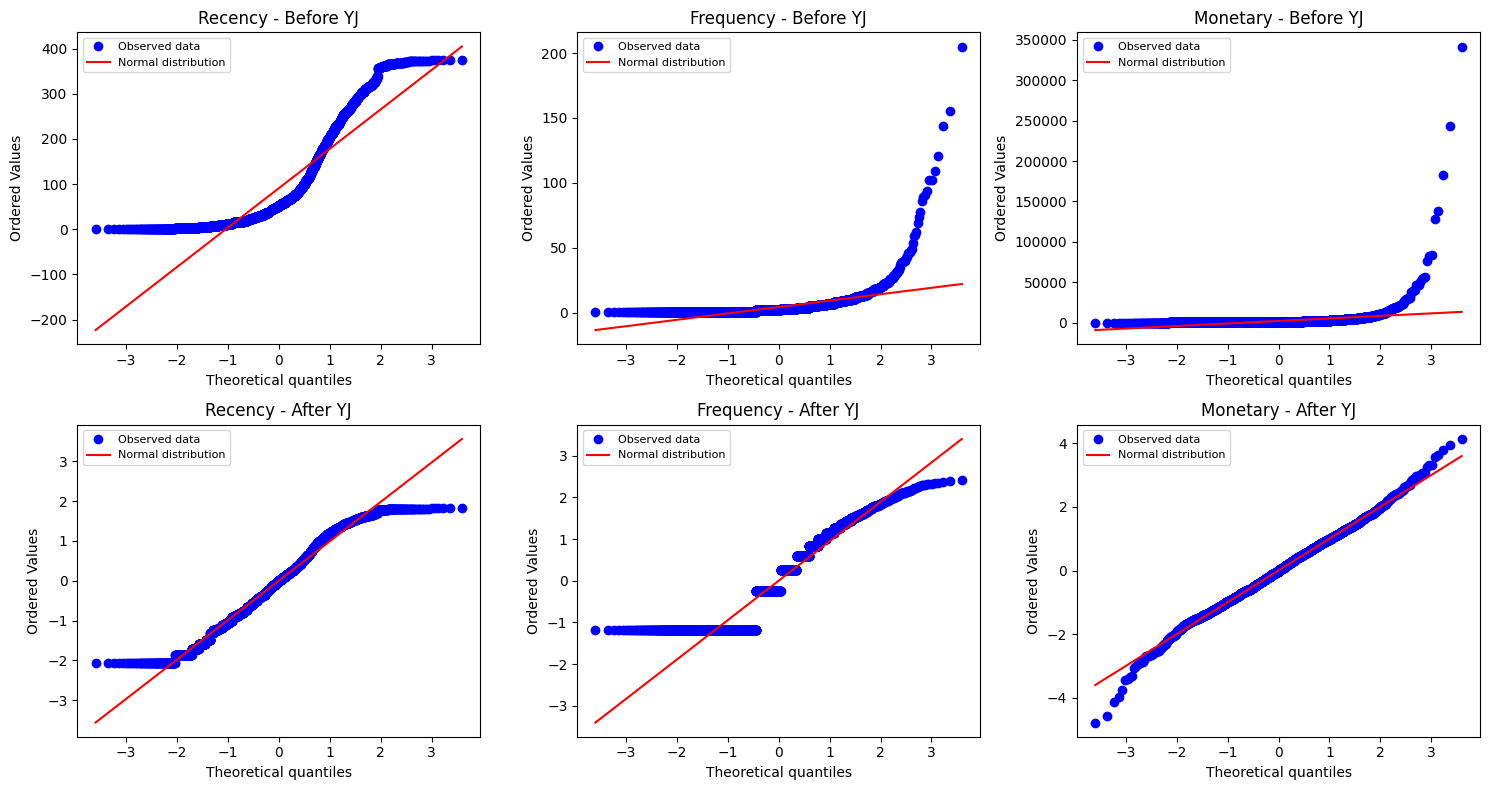

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer
from sklearn.pipeline import Pipeline
import scipy.stats as stats

# Prepare RFM data for clustering
rfm_features = rfm_df[['Recency', 'Frequency', 'Monetary']]

# Handle skewness and scale data
preprocessor = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=True))
])

rfm_transformed = preprocessor.fit_transform(rfm_features)
rfm_scaled_df = pd.DataFrame(rfm_transformed, columns=rfm_features.columns)

# Q-Q plots: before vs after Yeo-Johnson transformed
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes[0], rfm_features.columns):
    stats.probplot(rfm_features[col], dist="norm", plot=ax)
    ax.set_title(f'{col} - Before YJ')
    ax.get_lines()[0].set_label('Observed data')
    ax.get_lines()[1].set_label('Normal distribution')
    ax.legend(fontsize=8)

for ax, col in zip(axes[1], rfm_scaled_df.columns):
    stats.probplot(rfm_scaled_df[col], dist="norm", plot=ax)
    ax.set_title(f'{col} - After YJ')
    ax.get_lines()[0].set_label('Observed data')
    ax.get_lines()[1].set_label('Normal distribution')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

There is a substantial improvement in normality across all three features.

* **Recency:** S-curve still remains but is compressed and straightened. The flat tails represent groups of customers sharing identical values - one cluster at the minimum value (customers whose last non-cancelled purchase occurred on the reference date) and another at the maximum value (customers whose last non-cancelled purchase occurred near the start of the observation window, indicating no repeated engagement since).

* **Frequency:** the distribution now closely follows the expected pattern of a normal distribution through the middle of its range. A flat shelf remains on the left, likely representing the many customers with a single purchase.

* **Monetary:** the distribution closely follows the expected pattern of a normal distribution across nearly its full range, with only mild deviation at both tails. The upper-tail deviation reflects a small number of customers with extreme spending, addressed separately below.

## Handling Extreme Monetary Outliers

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer

rfm_cols = ['Recency', 'Frequency', 'Monetary']

monetary_mean = rfm_scaled_df['Monetary'].mean()
monetary_std = rfm_scaled_df['Monetary'].std()

# identify outliers (monetary values >= 3 standard deviations above the mean)
upper_threshold = monetary_mean + (3 * monetary_std)
monetary_outliers_scaled = rfm_scaled_df[rfm_scaled_df['Monetary'] >= upper_threshold]

print(f"Number of customers with 'Monetary' values >= 3 std dev above mean (after transformation): {len(monetary_outliers_scaled)}")

# get the indices of these outliers
outlier_indices = monetary_outliers_scaled.index

# the manually flagged group, kept for separate reporting
assert (rfm_scaled_df.index == rfm_df.index).all(), "Index misalignment between scaled and raw data"
manual_flagged_df = rfm_df.loc[outlier_indices]

print("\nRaw (non-standardized) RFM values for these outliers:")
display(manual_flagged_df)

# remove these customers from the unscaled rfm_df for consistency
rfm_df_no_outliers = rfm_df.drop(outlier_indices).reset_index(drop=True)

# refit the transformer on the population actually being clustered
final_preprocessor = Pipeline([
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=True))
])

rfm_scaled_df_no_outliers = pd.DataFrame(
    final_preprocessor.fit_transform(rfm_df_no_outliers[rfm_cols]),
    columns=rfm_cols
)

print(f"Remaining customers: {rfm_scaled_df_no_outliers.shape[0]}")

Number of customers with 'Monetary' values >= 3 std dev above mean (after transformation): 12

Raw (non-standardized) RFM values for these outliers:


,Customer ID,Recency,Frequency,Monetary
501,13089,4,109,55801.73
930,13694,9,94,128172.42
1257,14156,7,102,183163.55
1619,14646,10,78,243853.05
1819,14911,1,205,137710.76
1929,15061,3,86,82162.74
2110,15311,1,121,54033.21
3099,16684,15,27,75610.17
3148,16754,8,29,54558.18
3711,17511,3,31,83760.60


Remaining customers: 4264


These 12 customers have unusually high spending (£50K-£342K) and purchase counts (27-205 orders), atypical for individual retail behavior and consistent with possible wholesale/B2B activity mixed into the dataset. Further data would be needed to confirm this so they are separated and reported as a manually-flagged segment. **If these values genuinely reflect retail (B2C) behavior, this segment would represent a 'Champions' tier: customers who are simultaneously the most recent, frequent, and highest-spending in the dataset.**

# Modeling and Analysis

### Selecting the Number of Clusters

With extreme monetary outliers separated and the remaining features transformed
and standardized, K-means is applied across a range of cluster counts (k) to identify the segmentation that best balances statistical fit with business interpretability. Two metrics are used to guide this: the elbow method (inertia/within-cluster sum of squares) and the silhouette score, which measures how well-separated and cohesive each cluster is:

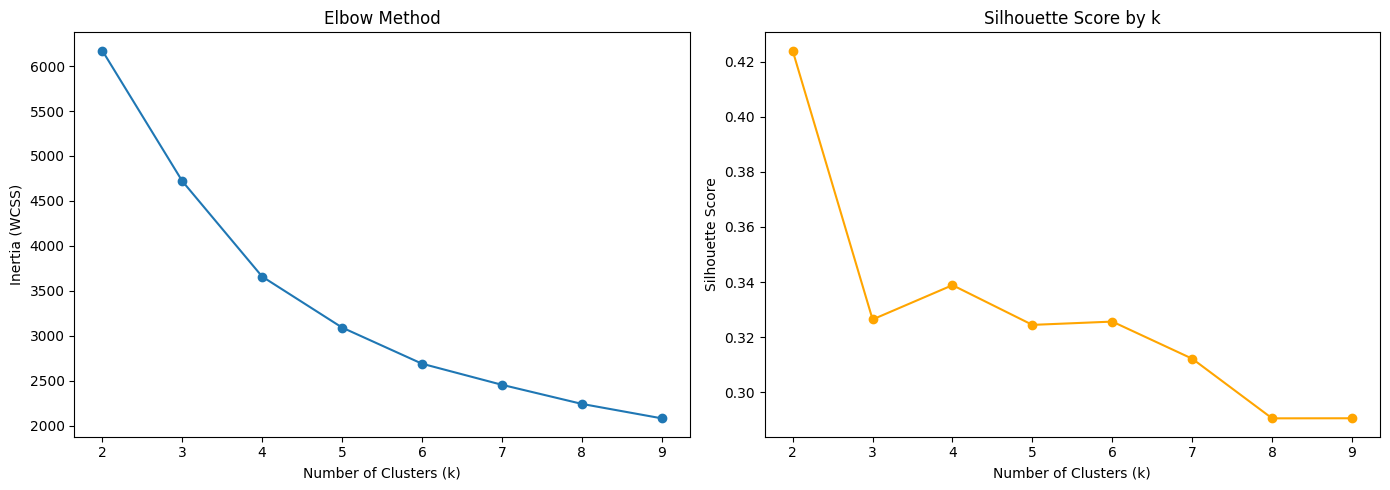

k=2: Inertia=6170.85, Silhouette=0.4240
k=3: Inertia=4720.47, Silhouette=0.3264
k=4: Inertia=3658.61, Silhouette=0.3389
k=5: Inertia=3092.20, Silhouette=0.3245
k=6: Inertia=2690.13, Silhouette=0.3257
k=7: Inertia=2455.55, Silhouette=0.3122
k=8: Inertia=2243.09, Silhouette=0.2906
k=9: Inertia=2082.48, Silhouette=0.2906


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Range of k values to test
k_range = range(2, 10)

inertia_values = []
silhouette_values = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    cluster_labels = kmeans.fit_predict(rfm_scaled_df_no_outliers)

    inertia_values.append(kmeans.inertia_)
    silhouette_values.append(silhouette_score(rfm_scaled_df_no_outliers, cluster_labels))

# Plot elbow (inertia) and silhouette side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Elbow plot
axes[0].plot(k_range, inertia_values, marker='o')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method')
axes[0].set_xticks(list(k_range))

# Silhouette plot
axes[1].plot(k_range, silhouette_values, marker='o', color='orange')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k')
axes[1].set_xticks(list(k_range))

plt.tight_layout()
plt.show()

# Print values for reference
for k, inertia, sil in zip(k_range, inertia_values, silhouette_values):
    print(f"k={k}: Inertia={inertia:.2f}, Silhouette={sil:.4f}")

While silhouette score reaches its global maximum at `k=2`, this reflects only a coarse split. `k=4` is a local peak (0.34) and the highest silhouette score for any value of k greater or equal to 3. The elbow curve shows no sharp bend, but the reduction in inertia per additional cluster roughly halves after `k=4`, making it a reasonable candidate for the number of customer segments. Taking a deeper look at this by calculating summary statistics:


k = 4


,Count,Recency_mean,Recency_median,Frequency_mean,Frequency_median,Monetary_mean,Monetary_median,Pct_of_Total
Cluster,,,,,,,,
3,1118,16.5,12.0,9.9,7.0,4164.6,2486.5,26.2
1,1150,94.2,73.0,3.6,3.0,1370.8,1024.0,27.0
0,978,34.6,30.0,1.5,1.0,415.5,344.2,22.9
2,1018,223.1,225.0,1.2,1.0,274.7,221.6,23.9


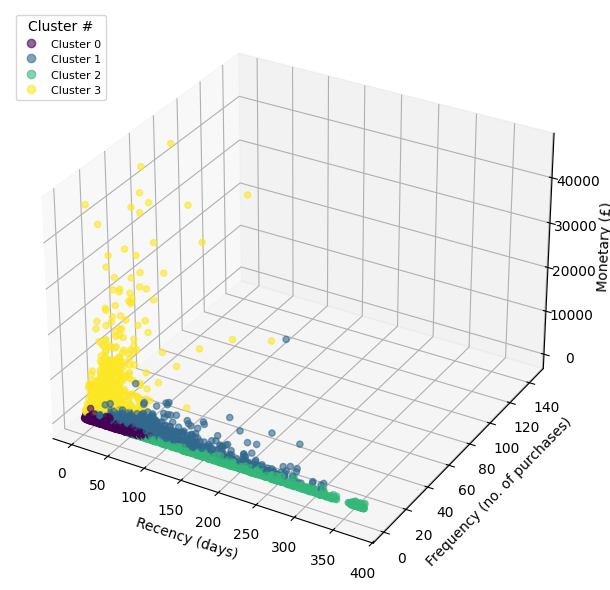

In [17]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import pandas as pd

def profile_clusters(k, rfm_scaled_df_no_outliers, rfm_features_raw):
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(rfm_scaled_df_no_outliers)

    # Attach cluster labels to the RAW (untransformed) RFM values for interpretability
    profile_df = rfm_features_raw.copy()
    profile_df['Cluster'] = labels

    summary = profile_df.groupby('Cluster').agg(
        Count=('Cluster', 'size'),
        Recency_mean=('Recency', 'mean'),
        Recency_median=('Recency', 'median'),
        Frequency_mean=('Frequency', 'mean'),
        Frequency_median=('Frequency', 'median'),
        Monetary_mean=('Monetary', 'mean'),
        Monetary_median=('Monetary', 'median')
    ).round(1)

    summary['Pct_of_Total'] = (summary['Count'] / len(profile_df) * 100).round(1)

    # Sort by median Monetary (more robust to skew than the mean)
    summary = summary.sort_values('Monetary_median', ascending=False)

    print(f"\n{'='*50}")
    print(f"k = {k}")
    print(f"{'='*50}")
    display(summary)

    return labels, summary

# Run for k = 4
results = {}
candidate_k_values = [4]
for k in candidate_k_values:
    labels, summary = profile_clusters(k, rfm_scaled_df_no_outliers, rfm_df_no_outliers[['Recency', 'Frequency', 'Monetary']])
    results[k] = {'labels': labels, 'summary': summary}

print(f"\n{'='*50}\n")

# 3D Visualization
fig = plt.figure(figsize=(18, 6))
for i, k in enumerate(candidate_k_values, start=1):
    ax = fig.add_subplot(1, len(candidate_k_values), i, projection='3d')
    scatter = ax.scatter(
        rfm_df_no_outliers['Recency'],
        rfm_df_no_outliers['Frequency'],
        rfm_df_no_outliers['Monetary'],
        c=results[k]['labels'], cmap='viridis', alpha=0.6
    )
    ax.set_xlabel('Recency (days)')
    ax.set_ylabel('Frequency (no. of purchases)')
    ax.set_zlabel('Monetary (£)')

    # Add a legend mapping colors to cluster numbers
    legend_elements = scatter.legend_elements()[0]
    cluster_labels = sorted(set(results[k]['labels']))
    ax.legend(legend_elements, [f'Cluster {c}' for c in cluster_labels],
              loc='upper left', fontsize=8, title='Cluster #')

plt.tight_layout()
plt.show()

### Assigning Labels to Clusters

All four segments are well-balanced (~23-27% of the total customers in the dataset) and well-defined.

- **Cluster 3 = Loyal High-Value**: recently active and frequent purchasers with the highest average spend.
- **Cluster 1 = At Risk**: Moderate historical engagement but recency has begun to slip (~2-3 months since last purchase).
- **Cluster 0 = New / Low-Engagement**: Relatively recent purchase activity but low frequency and spend. Likely newer customers who have not yet built a purchase history or one-time buyers.
- **Cluster 2 = Lost / Long-Lapsed**: Minimal recent activity, low historical frequency and spend.

In [18]:
# map cluster numbers to business-friendly segment names
cluster_name_map = {
    3: 'Loyal High-Value',
    1: 'At Risk',
    0: 'New / Low-Engagement',
    2: 'Lost / Long Lapsed'
}

k = 4
labels = results[k]['labels']

# attach both numeric cluster and named segment to the raw RFM data
rfm_df_no_outliers['Cluster'] = labels
rfm_df_no_outliers['Segment'] = rfm_df_no_outliers['Cluster'].map(cluster_name_map)

print('Examples of 20 customers grouped into their relevant segments:')
display(
    rfm_df_no_outliers.groupby('Segment', group_keys=False)
    .sample(5, random_state=42)
    .sort_values('Segment')
)

Examples of 20 customers grouped into their relevant segments:


,Customer ID,Recency,Frequency,Monetary,Cluster,Segment
631,13276,33,3,1280.28,1,At Risk
2682,16121,26,3,575.48,1,At Risk
1614,14644,50,5,1297.01,1,At Risk
832,13567,64,4,1074.19,1,At Risk
2406,15751,96,11,1318.84,1,At Risk
1485,14474,215,1,711.23,2,Lost / Long Lapsed
541,13144,67,1,24.40,2,Lost / Long Lapsed
3704,17514,305,1,313.35,2,Lost / Long Lapsed
1701,14751,320,2,126.45,2,Lost / Long Lapsed
3539,17292,108,2,271.75,2,Lost / Long Lapsed


Segment labels describe a typical customer profile. Each profile can be described by the box-plots below:

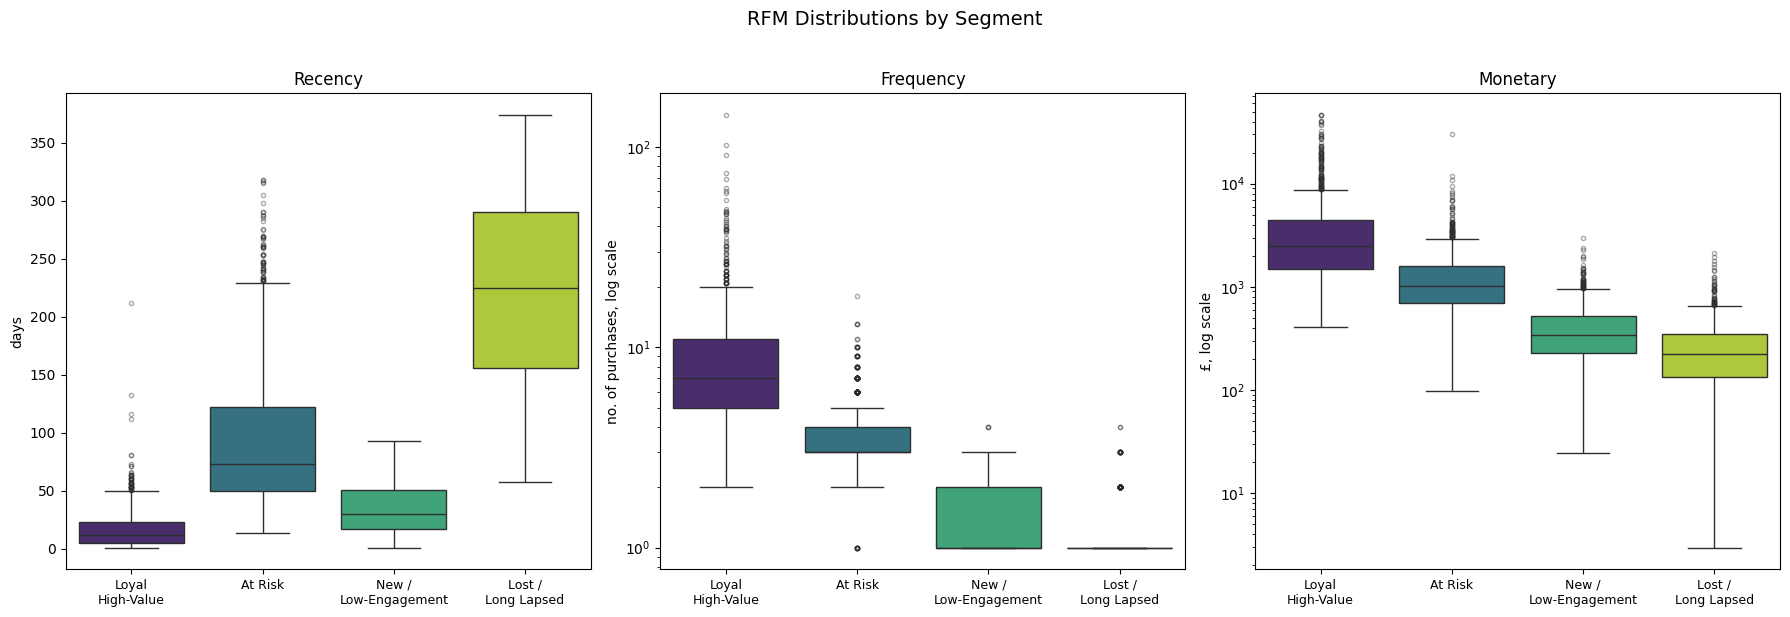

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

segment_order = ['Loyal High-Value', 'At Risk',
                 'New / Low-Engagement', 'Lost / Long Lapsed']
palette = dict(zip(segment_order, plt.cm.viridis([0.1, 0.4, 0.65, 0.9])))

features = [
    ('Recency', 'days', False),
    ('Frequency', 'no. of purchases, log scale', True),
    ('Monetary', '£, log scale', True),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (col, label, use_log) in zip(axes, features):
    sns.boxplot(
        data=rfm_df_no_outliers, x='Segment', y=col,
        order=segment_order, hue='Segment', palette=palette,
        legend=False, ax=ax, flierprops={'markersize': 3, 'alpha': 0.4}
    )
    if use_log:
        ax.set_yscale('log')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel(label)
    ax.set_xticks(range(len(segment_order)))
    ax.set_xticklabels([s.replace(' / ', ' /\n').replace(' High-Value', '\nHigh-Value')
                        for s in segment_order], fontsize=9)

plt.suptitle('RFM Distributions by Segment', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

### Analyzing Segment Profiles

**Loyal High-Value:** median recency is 12 days, median frequency is 7 purchases, and median monetary spending is about £2,487. The long upper
tails in frequency and monetary (up to 144 purchases and £46K) show that a small group of heavy buyers sits at the top of this segment.

**At Risk:** median recency is 73 days (IQR roughly 50-122), with a tail beyond 300 days. Median frequency is 3 purchases (IQR 3-4) and median monetary spending is about £1,024. These are repeat buyers whose activity has slowed. The recency tail and the high-spending outliers mark the most valuable customers to win back.

**New / Low-Engagement:** median recency is 30 days, and almost all customers have 1-2 purchases, with median monetary spending around £344. This profile fits newer or one-time buyers who have not yet built a purchase history.

**Lost / Long Lapsed:** median recency is 225 days (IQR roughly 156-291), frequency collapses to 1, and median monetary spending is about £222.

# Targeted Marketing Actions

Each segment's action follows from its RFM profile: protect value where it exists, recover it where it is slipping, and spend the least where the return is lowest.

**Loyal High-Value (goal: retain and grow)**
- Reward them with recognition and not discounts: early access to new products, a tiered loyalty program, personalized 'thank you' messaging.
- Run referral programs, since these customers are the most credible advocates.
- Heavy discounting is likely unnecessary, since these customers already buy frequently.

**At Risk (goal: win back before they lapse)**
- Send timed re-engagement campaigns when a customer's gap since last purchase
  passes their usual interval (for example, around 60-90 days).
- Use personalized 'we miss you' messages featuring products they have bought before, with a modest, time-limited incentive.
- Prioritize the high-spending members of this segment for stronger offers or personal outreach, since they are the most valuable customers at risk of leaving.
- This segment likely offers the best return on marketing spend: these customers have already shown repeated behavior, so reactivating them is easier than acquiring new ones.

**New / Low-Engagement (goal: convert to repeated buyers)**
- Run a welcome or onboarding sequence introducing the range and bestsellers.
- Send a second-purchase incentive within the first few weeks, such as free
  delivery or a small discount on a complementary product.
- Recommend products related to what they bought first.
- Track how many move into the 'At Risk' or 'Loyal High-Value' segments over time, since this segment's value comes from conversion.

**Lost / Long Lapsed (goal: low-cost reactivation)**
- Use low-cost, broad-reach campaigns such as one or two email attempts or
  seasonal promotions, instead of personalized or expensive outreach.
- Make a final win-back offer, then suppress non-responders from regular
  campaigns to cut cost.
- Send a short survey, if useful, to learn why they left.
- Expect a lower response rate here than in any other segment.

**Manually Flagged Group (12 customers, possible wholesale/B2B)**
- If they are B2B, handle them through account management with bulk-order incentives.
- If these are genuine retail customers, treat them as a top tier above 'Loyal High-Value', with personal outreach.

# Conclusion

This project segmented online retail customers using Recency, Frequency, and Monetary (RFM) metrics and K-Means clustering. Each segment was then paired with targeted marketing actions, as summarized in the table below:

| Segment | % of Customers | Profile (median) | Goal | Priority |
|---|---|---|---|---|
| Loyal High-Value | 26.2% | 12 days, 7 purchases, £2,487 | Retain and grow | Protect |
| At Risk | 27.0% | 73 days, 3 purchases, £1,024 | Win back before they lapse | Highest ROI |
| New / Low-Engagement | 22.9% | 30 days, 1 purchase, £344 | Convert to repeat buyers | Nurture |
| Lost / Long Lapsed | 23.9% | 225 days, 1 purchase, £222 | Low-cost reactivation | Low spend |

*percentages are of the 4,264 customers included in clustering, excluding the manually flagged group of 12 customers*

**Limitations**
- Customer behavior in this dataset is a continuum and not a set of sharply separated groups, so segment labels describe typical profiles and not every member.
- The nature of the manually flagged group could not be confirmed with RFM data alone. Further data would be needed to separate genuine high-value retail customers from wholesale accounts.
- The dataset covers a limited time window (2009-2010), so some customers' transaction histories are incomplete.

**Next steps**
- Tailor campaigns by country: country was not used in this analysis, but it can be reattached to the segments to compare segment mix and behavior across markets.
- Validate the marketing actions with controlled campaigns.
- Re-run the pipeline periodically on new transaction data and track how customers migrate between segments over time. Movement to/from segments is itself a useful signal.
- Explore soft clustering (e.g. Fuzzy C-Means), which gives each customer a membership score across segments and could better represent borderline customers than a single hard label.